In [1]:
import pandas as pd
import numpy as np
import os

# ================================================================
# ÉTAPE 1 (CORRIGÉE) : CONNEXION DRIVE ET NETTOYAGE ROBUSTE
# ================================================================

# 1. Connexion au Google Drive et définition du dossier
# Sur Google Colab : on monte le Drive. Ailleurs (exécution locale) : on lit le dossier
# indiqué par la variable d'environnement PROJECT_DIR, ou à défaut le dossier courant.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/Othercomputers/mi_compu/projet_bnbupgrade"
except ImportError:
    PROJECT_DIR = os.environ.get('PROJECT_DIR', '.')

print("\nDossier projet :", PROJECT_DIR)
print("Fichiers présents :", os.listdir(PROJECT_DIR))
print("="*64)

# 2. Chargement des données depuis le Drive
chemin_fichier = os.path.join(PROJECT_DIR, 'riviera_du_levant.csv')
df = pd.read_csv(chemin_fichier, encoding='utf-8-sig')
nb_brutes = len(df)  # taille de l'export brut, avant tout nettoyage
# ================================================================
# VALIDATION DE L'INTÉGRITÉ DES LIGNES (détection du bug de quoting CSV)
# ================================================================
# Certains noms d'annonces contiennent des guillemets mal échappés
# (ex: Residence ""vwal o van"" 1""), ce qui décale toutes les colonnes
# suivantes lors du parsing. On détecte ces lignes via listing_id,
# qui doit toujours être un identifiant numérique valide.

def est_id_valide(valeur):
    try:
        int(valeur)
        return True
    except (ValueError, TypeError):
        return False

mask_corrompu = ~df['listing_id'].apply(est_id_valide)
nb_corrompues = mask_corrompu.sum()

if nb_corrompues > 0:
    print(f"\n {nb_corrompues} ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.")
    df = df[~mask_corrompu].copy()
else:
    print("\nAucune ligne corrompue détectée.")

nb_apres_corrompues = len(df)
print(f" DÉMARRAGE : {nb_brutes} lignes dans l'export brut, {nb_apres_corrompues} après retrait des lignes corrompues")
print("="*64)

# ================================================================
# RAPPORT DE QUALITÉ DES DONNÉES (valeurs manquantes avant nettoyage)
# ================================================================
print("\nVALEURS MANQUANTES AVANT NETTOYAGE (sur les données brutes)")
print("="*64)

manquants = df.isna().sum()
manquants = manquants[manquants > 0].sort_values(ascending=False)

if len(manquants) > 0:
    pourcentage = (manquants / len(df) * 100).round(1)
    df_manquants = pd.DataFrame({
        'Colonne': manquants.index,
        'Nb valeurs manquantes': manquants.values,
        '% du total': pourcentage.values
    })
    display(df_manquants)
else:
    print("Aucune valeur manquante détectée.")
print("="*64)

# 3. Forçage des types numériques (Sécurité anti-bug texte/NaN)
df['ttm_revenue'] = pd.to_numeric(df['ttm_revenue'], errors='coerce')
df['num_reviews'] = pd.to_numeric(df['num_reviews'], errors='coerce')

# Suppression des lignes où le revenu ou le nombre d'avis est manquant ou non numérique
nb_avant_na = len(df)
df = df.dropna(subset=['ttm_revenue', 'num_reviews']).copy()
nb_apres_na = len(df)

print(f"\n0. VALEURS MANQUANTES SUR LA CIBLE OU LES AVIS")
print(f"   Suppression de {nb_avant_na - nb_apres_na} annonces sans revenu ou sans nombre d'avis exploitable.")

# 4. Filtrage des inactifs et annonces trop récentes
SEUIL_REVENU = 2000
SEUIL_AVIS = 5

mask_inactifs = (df['ttm_revenue'] < SEUIL_REVENU) | (df['num_reviews'] < SEUIL_AVIS)
nb_inactifs = mask_inactifs.sum()

print(f"\n1. FILTRAGE RÉCENCE / INACTIVITÉ")
print(f"   Suppression de {nb_inactifs} annonces (Revenu < {SEUIL_REVENU}€ OU Avis < {SEUIL_AVIS}).")

df_active = df[~mask_inactifs].copy()

# 5. Traitement des valeurs aberrantes (Outliers) sur le revenu
Q1 = df_active['ttm_revenue'].quantile(0.25)
Q3 = df_active['ttm_revenue'].quantile(0.75)
IQR = Q3 - Q1
FACTEUR = 3.0  # Tolérant : coupe uniquement les extrêmes absolus

borne_haute = Q3 + (FACTEUR * IQR)

mask_outliers = df_active['ttm_revenue'] > borne_haute
nb_outliers = mask_outliers.sum()

print(f"\n2. FILTRAGE VALEURS EXTRÊMES (MÉTHODE IQR)")
print(f"   Plafond de revenu standard calculé : {borne_haute:,.0f} €")
print(f"   Suppression de {nb_outliers} annonces 'ultra-luxe' dépassant ce plafond.")

# 6. Création du dataset final propre
df_clean = df_active[~mask_outliers].copy().reset_index(drop=True)

print("\n" + "="*64)
print(f" BILAN DU NETTOYAGE")
print("="*64)
print(f" Entonnoir : {nb_brutes} brutes → {nb_apres_corrompues} (lignes corrompues) → {nb_apres_na} (valeurs manquantes)"
      f" → {len(df_active)} (inactives ou récentes) → {len(df_clean)} (valeurs extrêmes)")
print(f" Annonces conservées : {len(df_clean)}")
print(f" Revenu annuel moyen du marché analysé : {df_clean['ttm_revenue'].mean():,.0f} €")
print(f" Revenu annuel médian du marché analysé : {df_clean['ttm_revenue'].median():,.0f} €")

# 7. Sauvegarde sur le Drive
chemin_sauvegarde = os.path.join(PROJECT_DIR, 'riviera_du_levant_cleaned.csv')
df_clean.to_csv(chemin_sauvegarde, index=False, encoding='utf-8-sig')

print(f"\n Fichier sauvegardé avec succès dans : {chemin_sauvegarde}")

# Aperçu des premières lignes
display(df_clean.head())


Dossier projet : .
Fichiers présents : ['riviera_du_levant.csv']

 12 ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.
 DÉMARRAGE : 1220 lignes dans l'export brut, 1208 après retrait des lignes corrompues

VALEURS MANQUANTES AVANT NETTOYAGE (sur les données brutes)


,Colonne,Nb valeurs manquantes,% du total
0,bedrooms,111,9.2
1,guests,18,1.5
2,ttm_revenue,8,0.7
3,baths,8,0.7
4,superhost,8,0.7
5,num_reviews,8,0.7
6,pool,8,0.7
7,air_conditioning,8,0.7
8,dishwasher,8,0.7
9,dedicated_workspace,8,0.7



0. VALEURS MANQUANTES SUR LA CIBLE OU LES AVIS
   Suppression de 10 annonces sans revenu ou sans nombre d'avis exploitable.

1. FILTRAGE RÉCENCE / INACTIVITÉ
   Suppression de 10 annonces (Revenu < 2000€ OU Avis < 5).

2. FILTRAGE VALEURS EXTRÊMES (MÉTHODE IQR)
   Plafond de revenu standard calculé : 82,495 €
   Suppression de 25 annonces 'ultra-luxe' dépassant ce plafond.

 BILAN DU NETTOYAGE
 Entonnoir : 1220 brutes → 1208 (lignes corrompues) → 1198 (valeurs manquantes) → 1188 (inactives ou récentes) → 1163 (valeurs extrêmes)
 Annonces conservées : 1163
 Revenu annuel moyen du marché analysé : 23,683 €
 Revenu annuel médian du marché analysé : 19,286 €

 Fichier sauvegardé avec succès dans : ./riviera_du_levant_cleaned.csv


,listing_id,listing_name,ttm_revenue,bedrooms,guests,baths,superhost,num_reviews,pool,air_conditioning,dishwasher,dedicated_workspace,waterfront,hot_tub,sauna,ev_charger,bbq_grill,cable_tv,gym,locality
0,880610968870364779,"Villa Bleu Indigo 3 bedrooms, sea view, beach ...",80645.0,3.0,6.0,2.0,1.0,13.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,Sainte-Anne
1,549040206461580818,"Creole villa with panoramic sea view, Sainte-Anne",78287.0,3.0,8.0,3.0,0.0,49.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,Sainte-Anne
2,638934451525248024,Villa Kouleur Kafé – Sea view & infinity pool,77737.0,6.0,15.0,4.5,1.0,5.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,Sainte-Anne
3,12971707,Beautiful Villa ideally located in Sainte-Anne,77008.0,5.0,10.0,3.0,1.0,127.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,Sainte-Anne
4,16452190,Yin and Yang Villa with panoramic sea view Sai...,76945.0,4.0,12.0,3.0,1.0,20.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,Sainte-Anne


 Chargement réussi : 1163 annonces prêtes pour l'analyse.

 1. IMPACT BRUT DES ÉQUIPEMENTS SUR LE REVENU ANNUEL (TTM Revenue)


,Equipement,Nb_Logements_Avec,Revenu_Moyen_Avec (€),Revenu_Moyen_Sans (€),Ecart_Brut (€)
6,sauna,2,46006.0,23645.0,22362.0
2,dishwasher,484,32164.0,17638.0,14526.0
0,pool,741,27665.0,16693.0,10972.0
1,air_conditioning,1147,23805.0,14939.0,8866.0
8,bbq_grill,509,28479.0,19951.0,8528.0
5,hot_tub,78,29941.0,23234.0,6707.0
3,dedicated_workspace,427,26750.0,21904.0,4846.0
10,gym,232,25141.0,23320.0,1820.0
4,waterfront,358,24152.0,23475.0,677.0
9,cable_tv,108,23844.0,23667.0,177.0



 2. VISUALISATION : ÉCART DE REVENU PAR ÉQUIPEMENT


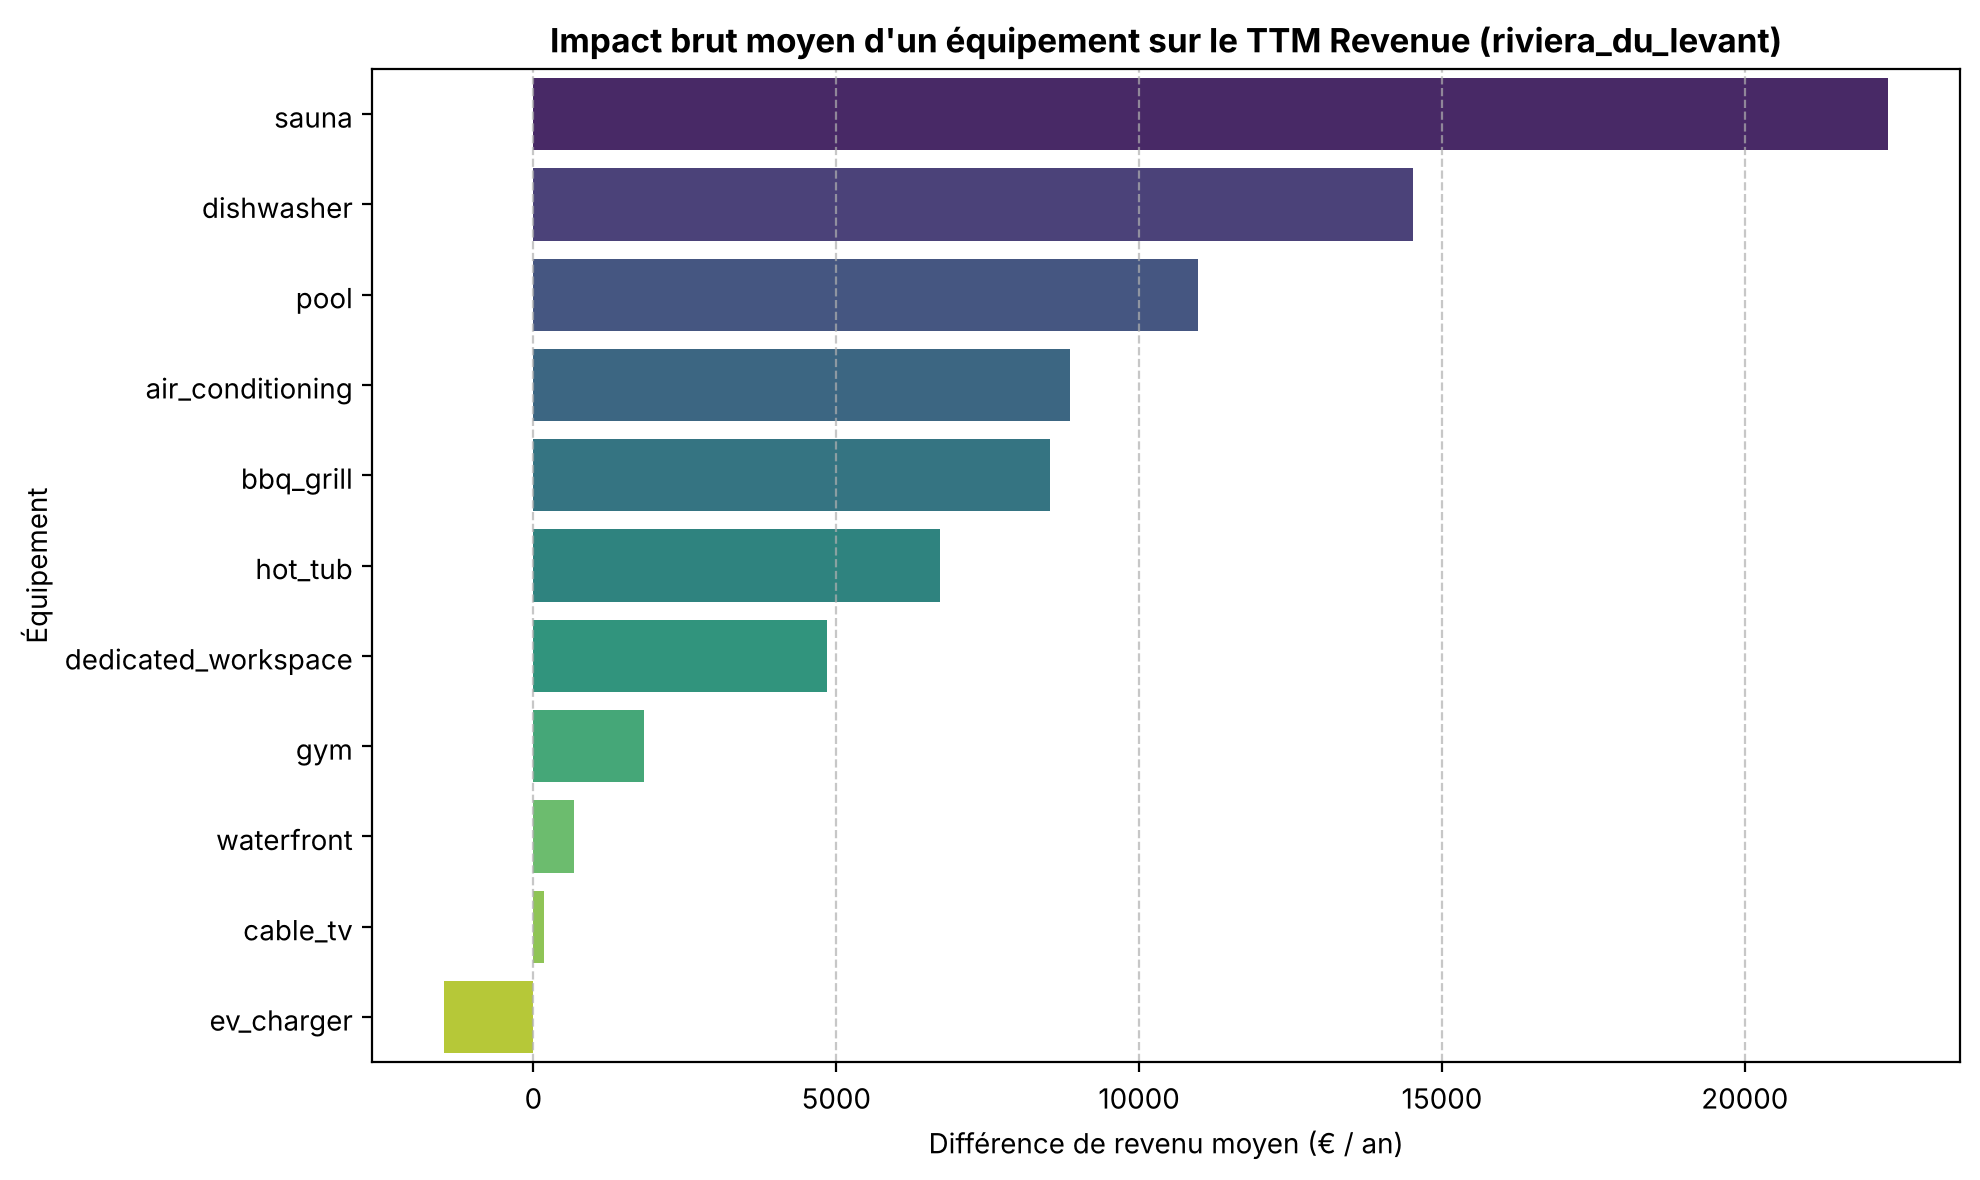


 Graphique sauvegardé dans : ./impact_equipements_brut.png


In [2]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

# ================================================================
# ÉTAPE 2 : ANALYSE EXPLORATOIRE ET IMPACT BRUT DES FEATURES
# ================================================================

# 1. Chargement du fichier propre depuis le Drive
chemin_fichier = os.path.join(PROJECT_DIR, 'riviera_du_levant_cleaned.csv')
df_clean = pd.read_csv(chemin_fichier, encoding='utf-8-sig')

print(f" Chargement réussi : {len(df_clean)} annonces prêtes pour l'analyse.\n")
print("="*64)
print(" 1. IMPACT BRUT DES ÉQUIPEMENTS SUR LE REVENU ANNUEL (TTM Revenue)")
print("="*64)

# Liste des équipements binaires présents dans la base
amenities_cols = [
    'pool', 'air_conditioning', 'dishwasher', 'dedicated_workspace',
    'waterfront', 'hot_tub', 'sauna', 'ev_charger', 'bbq_grill', 'cable_tv', 'gym'
]

# Calcul de l'impact brut pour chaque équipement
resultats_impact = []
for col in amenities_cols:
    if col in df_clean.columns:
        rev_avec = df_clean[df_clean[col] == 1]['ttm_revenue'].mean()
        rev_sans = df_clean[df_clean[col] == 0]['ttm_revenue'].mean()
        nb_avec = (df_clean[col] == 1).sum()
        diff = rev_avec - rev_sans

        resultats_impact.append({
            'Equipement': col,
            'Nb_Logements_Avec': nb_avec,
            'Revenu_Moyen_Avec (€)': round(rev_avec, 0),
            'Revenu_Moyen_Sans (€)': round(rev_sans, 0),
            'Ecart_Brut (€)': round(diff, 0)
        })

df_impact = pd.DataFrame(resultats_impact).sort_values(by='Ecart_Brut (€)', ascending=False)
display(df_impact)

print("\n" + "="*64)
print(" 2. VISUALISATION : ÉCART DE REVENU PAR ÉQUIPEMENT")
print("="*64)

# Génération d'un graphique propre pour visualiser les écarts
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_impact,
    x='Ecart_Brut (€)',
    y='Equipement',
    hue='Equipement',
    palette='viridis',
    legend=False
)
plt.title("Impact brut moyen d'un équipement sur le TTM Revenue (riviera_du_levant)", fontsize=12, fontweight='bold')
plt.xlabel("Différence de revenu moyen (€ / an)", fontsize=10)
plt.ylabel("Équipement", fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()

# Sauvegarde du graphique sur le Drive
graph_path = os.path.join(PROJECT_DIR, 'impact_equipements_brut.png')
plt.savefig(graph_path, dpi=300)
plt.show()

print(f"\n Graphique sauvegardé dans : {graph_path}")

In [3]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# ================================================================
# ÉTAPE PROPRE : FILTRAGE DES BRUITS & MODÉLISATION CORRIGÉE
# ================================================================

# 1. Chargement du fichier fusionné d'origine
chemin_fichier = os.path.join(PROJECT_DIR, 'riviera_du_levant.csv')
df = pd.read_csv(chemin_fichier, encoding='utf-8-sig')
# ================================================================
# VALIDATION DE L'INTÉGRITÉ DES LIGNES (détection du bug de quoting CSV)
# ================================================================
# Certains noms d'annonces contiennent des guillemets mal échappés
# (ex: Residence ""vwal o van"" 1""), ce qui décale toutes les colonnes
# suivantes lors du parsing. On détecte ces lignes via listing_id,
# qui doit toujours être un identifiant numérique valide.

def est_id_valide(valeur):
    try:
        int(valeur)
        return True
    except (ValueError, TypeError):
        return False

mask_corrompu = ~df['listing_id'].apply(est_id_valide)
nb_corrompues = mask_corrompu.sum()

if nb_corrompues > 0:
    print(f"\n {nb_corrompues} ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.")
    df = df[~mask_corrompu].copy()
else:
    print("\nAucune ligne corrompue détectée.")

print(f" Chargement initial : {len(df)} annonces")

# 2. Forçage des types et nettoyage initial
df['ttm_revenue'] = pd.to_numeric(df['ttm_revenue'], errors='coerce')
df['num_reviews'] = pd.to_numeric(df['num_reviews'], errors='coerce')
df = df.dropna(subset=['ttm_revenue', 'num_reviews']).copy()

# 3. Filtrage inactifs et récents
SEUIL_REVENU = 2000
SEUIL_AVIS = 5
mask_inactifs = (df['ttm_revenue'] < SEUIL_REVENU) | (df['num_reviews'] < SEUIL_AVIS)
df_active = df[~mask_inactifs].copy()

# 4. Suppression des outliers (méthode IQR)
Q1 = df_active['ttm_revenue'].quantile(0.25)
Q3 = df_active['ttm_revenue'].quantile(0.75)
IQR = Q3 - Q1
borne_haute = Q3 + (3.0 * IQR)
df_clean = df_active[~(df_active['ttm_revenue'] > borne_haute)].copy().reset_index(drop=True)

# 5. NETTOYAGE DU BRUIT (Suppression des colonnes inutiles ou aberrantes)
# On jette explicitement l'ID et le nom (qui ne sont pas des features mathématiques)
# On retire 'sauna' : équipement quasi absent du marché, donc inexploitable (décompte affiché ci-dessous).
# 'ev_charger' n'est pas non plus retenu dans la liste des variables du modèle.
for col_rare in ['sauna', 'ev_charger']:
    nb_equipes = int(pd.to_numeric(df_clean[col_rare], errors='coerce').sum())
    print(f" Variable écartée '{col_rare}' : {nb_equipes} logements équipés sur {len(df_clean)}")
if 'sauna' in df_clean.columns:
    df_clean = df_clean.drop(columns=['sauna'])

# 6. Encodage propre de la commune (locality)
df_encoded = pd.get_dummies(df_clean, columns=['locality'], drop_first=True, dtype=int)

# 7. Sélection stricte des features utiles (l'ID est exclu d'office)
features = [
    'bedrooms', 'guests', 'baths', 'superhost', 'num_reviews',
    'pool', 'air_conditioning', 'dishwasher', 'dedicated_workspace',
    'waterfront', 'hot_tub', 'bbq_grill', 'cable_tv', 'gym'
]

# Ajout dynamique des colonnes de localité
loc_cols = [c for c in df_encoded.columns if c.startswith('locality_')]
features.extend(loc_cols)

X = df_encoded[features]
y = df_encoded['ttm_revenue']

# 8. Split Train / Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 9. Imputation des valeurs manquantes (médiane)
imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=features)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=features)

# 10. Normalisation RobustScaler
scaler = RobustScaler()
cols_to_scale = ['bedrooms', 'guests', 'baths', 'num_reviews']
X_train_scaled = X_train_imputed.copy()
X_test_scaled = X_test_imputed.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train_imputed[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test_imputed[cols_to_scale])

# 11. Entraînement du modèle Ridge
model = Ridge(alpha=10.0) # alpha un peu plus fort pour stabiliser les coefficients
model.fit(X_train_scaled, y_train)

# 12. Résultats
y_pred = model.predict(X_test_scaled)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("="*64)
print(f" NETTOYAGE TERMINÉ : {len(df_clean)} annonces conservées")
print(f" R² : {r2:.2f} | MAE : ± {mae:,.0f} € / an")
print("="*64)

df_coefs = pd.DataFrame({
    'Feature': features,
    'Impact_Annuel_Euros': model.coef_
}).sort_values(by='Impact_Annuel_Euros', ascending=False)

print(df_coefs.to_string(index=False))
print(f"\n Constante (intercept) : {model.intercept_:,.0f} €")
print(" Lecture : pour bedrooms, guests, baths et num_reviews, le coefficient correspond à une variation")
print(" d'un écart interquartile (RobustScaler) : " + ", ".join(f"{c} = {e:g}" for c, e in zip(cols_to_scale, scaler.scale_)))


 12 ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.
 Chargement initial : 1208 annonces
 Variable écartée 'sauna' : 2 logements équipés sur 1163
 Variable écartée 'ev_charger' : 40 logements équipés sur 1163


 NETTOYAGE TERMINÉ : 1163 annonces conservées
 R² : 0.54 | MAE : ± 7,690 € / an
                Feature  Impact_Annuel_Euros
                   pool          5618.330090
             dishwasher          5259.935519
               bedrooms          4463.468218
              superhost          3681.529012
                  baths          3336.587396
                    gym          2796.470206
       air_conditioning          2221.694128
    dedicated_workspace          2121.231734
              bbq_grill          1733.149263
            num_reviews          1232.937650
                hot_tub          1177.917510
             waterfront           905.148461
   locality_Sainte-Anne           813.057595
                 guests          -248.908274
               cable_tv          -942.903779
locality_Saint-François         -1832.215303

 Constante (intercept) : 5,739 €
 Lecture : pour bedrooms, guests, baths et num_reviews, le coefficient correspond à une variation
 d'un écart interquarti

In [4]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
import joblib

# ================================================================
# CORRECTION ET MISE EN PLACE PROPRE DU SIMULATEUR
# ================================================================

# 1. Chargement et préparation rigoureuse
chemin_fichier = os.path.join(PROJECT_DIR, 'riviera_du_levant.csv')
df = pd.read_csv(chemin_fichier, encoding='utf-8-sig')
# ================================================================
# VALIDATION DE L'INTÉGRITÉ DES LIGNES (détection du bug de quoting CSV)
# ================================================================
# Certains noms d'annonces contiennent des guillemets mal échappés
# (ex: Residence ""vwal o van"" 1""), ce qui décale toutes les colonnes
# suivantes lors du parsing. On détecte ces lignes via listing_id,
# qui doit toujours être un identifiant numérique valide.

def est_id_valide(valeur):
    try:
        int(valeur)
        return True
    except (ValueError, TypeError):
        return False

mask_corrompu = ~df['listing_id'].apply(est_id_valide)
nb_corrompues = mask_corrompu.sum()

if nb_corrompues > 0:
    print(f"\n {nb_corrompues} ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.")
    df = df[~mask_corrompu].copy()
else:
    print("\nAucune ligne corrompue détectée.")

df['ttm_revenue'] = pd.to_numeric(df['ttm_revenue'], errors='coerce')
df['num_reviews'] = pd.to_numeric(df['num_reviews'], errors='coerce')
df = df.dropna(subset=['ttm_revenue', 'num_reviews']).copy()

SEUIL_REVENU = 2000
SEUIL_AVIS = 5
mask_inactifs = (df['ttm_revenue'] < SEUIL_REVENU) | (df['num_reviews'] < SEUIL_AVIS)
df_active = df[~mask_inactifs].copy()

Q1 = df_active['ttm_revenue'].quantile(0.25)
Q3 = df_active['ttm_revenue'].quantile(0.75)
IQR = Q3 - Q1
borne_haute = Q3 + (3.0 * IQR)
df_clean = df_active[~(df_active['ttm_revenue'] > borne_haute)].copy().reset_index(drop=True)

# 2. Encodage
df_encoded = pd.get_dummies(df_clean, columns=['locality'], drop_first=True, dtype=int)

# 3. Liste de référence unique et stricte des features
#    (les 16 mêmes variables que le modèle Ridge de l'étape précédente, sans 'ev_charger')
features_reference = [
    'bedrooms', 'guests', 'baths', 'superhost', 'num_reviews',
    'pool', 'air_conditioning', 'dishwasher', 'dedicated_workspace',
    'waterfront', 'hot_tub', 'bbq_grill', 'cable_tv', 'gym'
]
loc_cols = [c for c in df_encoded.columns if c.startswith('locality_')]
features_reference.extend(loc_cols)

X = df_encoded[features_reference]
y = df_encoded['ttm_revenue']

# 4. Entraînement propre avec les DataFrames conservant les noms de colonnes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train), columns=features_reference)
X_test_imputed = pd.DataFrame(imputer.transform(X_test), columns=features_reference)

scaler = RobustScaler()
cols_to_scale = ['bedrooms', 'guests', 'baths', 'num_reviews']
X_train_scaled = X_train_imputed.copy()
X_test_scaled = X_test_imputed.copy()

X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train_imputed[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test_imputed[cols_to_scale])

modele = Ridge(alpha=10.0)
modele.fit(X_train_scaled, y_train)

# Sauvegarde des objets propres
joblib.dump(modele, os.path.join(PROJECT_DIR, 'modele_revenu_airbnb.pkl'))
joblib.dump(scaler, os.path.join(PROJECT_DIR, 'scaler_airbnb.pkl'))
joblib.dump(imputer, os.path.join(PROJECT_DIR, 'imputer_airbnb.pkl'))
joblib.dump(features_reference, os.path.join(PROJECT_DIR, 'features_reference.pkl'))

print(" Modèle et composants ré-entraînés et sauvegardés avec succès !")

# ================================================================
# AVERTISSEMENT MÉTHODOLOGIQUE : À LIRE AVANT D'UTILISER LE SIMULATEUR
# ================================================================
print("="*70)
print("  AVERTISSEMENT : CORRÉLATION ≠ CAUSALITÉ")
print("="*70)
print(" Ce simulateur repose sur une régression Ridge entraînée sur des")
print(" données OBSERVATIONNELLES (annonces existantes), et non sur une")
print(" expérience contrôlée.")
print()
gain_piscine = modele.coef_[features_reference.index('pool')]
print(f" Les gains affichés (ex: 'ajouter une piscine → +{gain_piscine:,.0f} €/an') sont")
print(" des ASSOCIATIONS STATISTIQUES, pas des effets causaux garantis.")
print(" Exemple de facteur confondant : les piscines sont surreprésentées")
print(" dans les grandes villas de luxe : le modèle peut donc capter en")
print(" partie l'effet du standing du bien plutôt que celui de la piscine")
print(" elle-même.")
print()
print(" → Ces estimations doivent être lues comme des INDICATEURS D'ORIENTATION,")
print("   pas comme des garanties de retour sur investissement.")
print("="*70)

# ================================================================
# FONCTION DU SIMULATEUR
# ================================================================
def simuler_revenu_logement(caracteristiques):
    df_input = pd.DataFrame([caracteristiques])
    for f in features_reference:
        if f not in df_input.columns:
            df_input[f] = 0
    df_input = df_input[features_reference]

    input_imputed = pd.DataFrame(imputer.transform(df_input), columns=features_reference)
    input_scaled = input_imputed.copy()
    input_scaled[cols_to_scale] = scaler.transform(input_imputed[cols_to_scale])

    revenu_estime = modele.predict(input_scaled)[0]
    return max(0, round(revenu_estime, 2))

def evaluer_ajout_equipement(logement_base, equipement_a_tester):
    rev_actuel = simuler_revenu_logement(logement_base)
    logement_modifie = logement_base.copy()
    logement_modifie[equipement_a_tester] = 1
    rev_avec_equipement = simuler_revenu_logement(logement_modifie)
    gain_additionnel = rev_avec_equipement - rev_actuel

    print("="*60)
    print(f" SIMULATION D'INVESTISSEMENT : Ajout de '{equipement_a_tester}'")
    print("="*60)
    print(f" • Revenu annuel estimé actuel : {rev_actuel:,.0f} €")
    print(f" • Revenu annuel estimé avec l'équipement : {rev_avec_equipement:,.0f} €")
    print(f" Association statistique observée : + {gain_additionnel:,.0f} € / an")
    print(f"   (corrélation, pas un effet causal démontré : voir avertissement ci-dessus)")
    print("="*60)

# ================================================================
# TEST DU SIMULATEUR
# ================================================================
mon_logement_actuel = {
    'bedrooms': 1,
    'guests': 3,
    'baths': 1,
    'superhost': 1,
    'num_reviews': 65,
    'pool': 0,
    'air_conditioning': 1,
    'dishwasher': 0,
    'dedicated_workspace': 0,
    'waterfront': 0,
    'hot_tub': 0,
    'bbq_grill': 0,
    'cable_tv': 1,
    'gym': 0,
    'locality_Saint-François': 0,   # 0 et 0 = Le Gosier (commune de référence)
    'locality_Sainte-Anne': 0
}

evaluer_ajout_equipement(mon_logement_actuel, 'dishwasher')
evaluer_ajout_equipement(mon_logement_actuel, 'pool')


 12 ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.
 Modèle et composants ré-entraînés et sauvegardés avec succès !
  AVERTISSEMENT : CORRÉLATION ≠ CAUSALITÉ
 Ce simulateur repose sur une régression Ridge entraînée sur des
 données OBSERVATIONNELLES (annonces existantes), et non sur une
 expérience contrôlée.

 Les gains affichés (ex: 'ajouter une piscine → +5,618 €/an') sont
 des ASSOCIATIONS STATISTIQUES, pas des effets causaux garantis.
 Exemple de facteur confondant : les piscines sont surreprésentées
 dans les grandes villas de luxe : le modèle peut donc capter en
 partie l'effet du standing du bien plutôt que celui de la piscine
 elle-même.

 → Ces estimations doivent être lues comme des INDICATEURS D'ORIENTATION,
   pas comme des garanties de retour sur investissement.
 SIMULATION D'INVESTISSEMENT : Ajout de 'dishwasher'
 • Revenu annuel estimé actuel : 11,567 €
 • Revenu annuel estimé avec l'équipement : 16,827 €
 Association statistique observé

In [5]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# ================================================================
# BENCHMARKING DE PLUSIEURS MODÈLES DE MACHINE LEARNING
# ================================================================

# 1. Chargement et préparation des données
chemin_fichier = os.path.join(PROJECT_DIR, 'riviera_du_levant.csv') if 'PROJECT_DIR' in locals() else 'riviera_du_levant.csv'
if not os.path.exists(chemin_fichier):
    chemin_fichier = 'riviera_du_levant.csv'

df = pd.read_csv(chemin_fichier, encoding='utf-8-sig')
# ================================================================
# VALIDATION DE L'INTÉGRITÉ DES LIGNES (détection du bug de quoting CSV)
# ================================================================
# Certains noms d'annonces contiennent des guillemets mal échappés
# (ex: Residence ""vwal o van"" 1""), ce qui décale toutes les colonnes
# suivantes lors du parsing. On détecte ces lignes via listing_id,
# qui doit toujours être un identifiant numérique valide.

def est_id_valide(valeur):
    try:
        int(valeur)
        return True
    except (ValueError, TypeError):
        return False

mask_corrompu = ~df['listing_id'].apply(est_id_valide)
nb_corrompues = mask_corrompu.sum()

if nb_corrompues > 0:
    print(f"\n {nb_corrompues} ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.")
    df = df[~mask_corrompu].copy()
else:
    print("\nAucune ligne corrompue détectée.")
df['ttm_revenue'] = pd.to_numeric(df['ttm_revenue'], errors='coerce')
df['num_reviews'] = pd.to_numeric(df['num_reviews'], errors='coerce')
df = df.dropna(subset=['ttm_revenue', 'num_reviews']).copy()

SEUIL_REVENU = 2000
SEUIL_AVIS = 5
mask_inactifs = (df['ttm_revenue'] < SEUIL_REVENU) | (df['num_reviews'] < SEUIL_AVIS)
df_active = df[~mask_inactifs].copy()

Q1 = df_active['ttm_revenue'].quantile(0.25)
Q3 = df_active['ttm_revenue'].quantile(0.75)
IQR = Q3 - Q1
borne_haute = Q3 + (3.0 * IQR)
df_clean = df_active[~(df_active['ttm_revenue'] > borne_haute)].copy().reset_index(drop=True)

df_encoded = pd.get_dummies(df_clean, columns=['locality'], drop_first=True, dtype=int)

features_reference = [
    'bedrooms', 'guests', 'baths', 'superhost', 'num_reviews',
    'pool', 'air_conditioning', 'dishwasher', 'dedicated_workspace',
    'waterfront', 'hot_tub', 'bbq_grill', 'cable_tv', 'gym'
]
loc_cols = [c for c in df_encoded.columns if c.startswith('locality_')]
features_reference.extend(loc_cols)

X = df_encoded[features_reference]
y = df_encoded['ttm_revenue']

# 2. Split Train / Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Imputation et Scaling
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = RobustScaler()
cols_to_scale = ['bedrooms', 'guests', 'baths', 'num_reviews']
# On applique le scaling sur les indices correspondants aux colonnes continues
col_indices = [features_reference.index(c) for c in cols_to_scale]

X_train_scaled = X_train_imp.copy()
X_test_scaled = X_test_imp.copy()
X_train_scaled[:, col_indices] = scaler.fit_transform(X_train_imp[:, col_indices])
X_test_scaled[:, col_indices] = scaler.transform(X_test_imp[:, col_indices])

# 4. Définition des 3 modèles à comparer
modeles = {
    "Régression Linéaire (Ridge)": Ridge(alpha=10.0),
    "Random Forest (Forêt Aléatoire)": RandomForestRegressor(n_estimators=150, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=42)
}

comparatif_resultats = []

for nom, modele in modeles.items():
    # Entraînement
    modele.fit(X_train_scaled, y_train)

    # Prédiction
    y_pred = modele.predict(X_test_scaled)

    # Métriques
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)

    comparatif_resultats.append({
        'Modèle': nom,
        'R² (Précision)': round(r2, 3),
        'MAE (Erreur en €)': round(mae, 0)
    })

    # Sauvegarde temporaire pour identifier le meilleur
    joblib.dump(modele, os.path.join(PROJECT_DIR if 'PROJECT_DIR' in locals() else '.', f'modele_{nom.lower().replace(" ", "_").replace("(", "").replace(")", "")}.pkl'))

df_comparatif = pd.DataFrame(comparatif_resultats).sort_values(by='R² (Précision)', ascending=False)

print("="*65)
print(" COMPARATIF DES PERFORMANCES DES MODÈLES (BENCHMARK)")
print("="*65)
print(df_comparatif.to_string(index=False))

# Sauvegarde de l'imputeur, du scaler et de la liste des features de référence
joblib.dump(scaler, os.path.join(PROJECT_DIR if 'PROJECT_DIR' in locals() else '.', 'scaler_airbnb.pkl'))
joblib.dump(imputer, os.path.join(PROJECT_DIR if 'PROJECT_DIR' in locals() else '.', 'imputer_airbnb.pkl'))
joblib.dump(features_reference, os.path.join(PROJECT_DIR if 'PROJECT_DIR' in locals() else '.', 'features_reference.pkl'))
print("\n Composants et modèles sauvegardés avec succès !")


 12 ligne(s) corrompue(s) détectée(s) (colonnes décalées) : retirées explicitement.


 COMPARATIF DES PERFORMANCES DES MODÈLES (BENCHMARK)
                         Modèle  R² (Précision)  MAE (Erreur en €)
Random Forest (Forêt Aléatoire)           0.560             7401.0
    Régression Linéaire (Ridge)           0.536             7690.0
           HistGradientBoosting           0.507             7695.0

 Composants et modèles sauvegardés avec succès !


In [6]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# ================================================================
# VALIDATION CROISÉE (5-FOLD) : DES SCORES PLUS FIABLES QU'UN SEUL SPLIT
# ================================================================
# Objectif : au lieu d'un seul train/test (sensible au hasard du split),
# on évalue chaque modèle sur 5 découpages différents et on regarde
# la moyenne ET l'écart-type du R² (stabilité du modèle).

# 1. Prétraitement propre inclus DANS le pipeline pour éviter toute fuite
#    de données entre les folds (imputation + normalisation refaites
#    à chaque pli, sur le train du pli uniquement)
cols_binaires = [c for c in features_reference if c not in cols_to_scale]

preprocesseur = ColumnTransformer(transformers=[
    ('continues', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), cols_to_scale),
    ('binaires', SimpleImputer(strategy='median'), cols_binaires)
])

# 2. Découpage en 5 plis, mélangé pour éviter tout effet d'ordre
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Évaluation de chaque modèle du dictionnaire "modeles" (défini dans la cellule de benchmark ci-dessus)
resultats_cv = []

for nom, modele in modeles.items():
    pipeline = Pipeline([
        ('preprocess', preprocesseur),
        ('model', modele)
    ])

    scores = cross_validate(
        pipeline, X, y,
        cv=cv,
        scoring=['r2', 'neg_mean_absolute_error'],
        n_jobs=-1
    )

    resultats_cv.append({
        'Modèle': nom,
        'R² moyen (CV)': round(scores['test_r2'].mean(), 3),
        'R² écart-type (CV)': round(scores['test_r2'].std(), 3),
        'MAE moyen (CV, €)': round(-scores['test_neg_mean_absolute_error'].mean(), 0)
    })

df_cv = pd.DataFrame(resultats_cv).sort_values(by='R² moyen (CV)', ascending=False)

print("="*70)
print(" VALIDATION CROISÉE (5-FOLD) : STABILITÉ DES SCORES PAR MODÈLE")
print("="*70)
print(df_cv.to_string(index=False))
print("\n Comparer 'R² moyen (CV)' au R² du split unique (df_comparatif) :")
print(" un grand écart entre les deux indique que le split initial était chanceux/malchanceux.")

 VALIDATION CROISÉE (5-FOLD) : STABILITÉ DES SCORES PAR MODÈLE
                         Modèle  R² moyen (CV)  R² écart-type (CV)  MAE moyen (CV, €)
    Régression Linéaire (Ridge)          0.571               0.038             7191.0
Random Forest (Forêt Aléatoire)          0.559               0.046             7155.0
           HistGradientBoosting          0.551               0.041             7295.0

 Comparer 'R² moyen (CV)' au R² du split unique (df_comparatif) :
 un grand écart entre les deux indique que le split initial était chanceux/malchanceux.


In [7]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import KFold
import numpy as np

# ================================================================
# IMPORTANCE DES FEATURES PAR PERMUTATION : MODÈLE RIDGE (validée en cross-validation)
# (le même calcul est refait plus bas sur le Random Forest réglé)
# ================================================================
# Contrairement aux coefficients Ridge (interprétables seulement à
# l'intérieur du modèle linéaire), la permutation importance mesure
# directement la perte de R² réelle quand le signal d'une feature est
# détruit : model-agnostic, donc comparable à d'autres modèles plus tard.
# Calculée sur les plis de validation (jamais sur le train) pour rester
# cohérent avec notre principe : pas de score sur des données déjà vues.

cv_perm = KFold(n_splits=5, shuffle=True, random_state=42)
importances_par_fold = []

for train_idx, val_idx in cv_perm.split(X):
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

    pipeline_fold = Pipeline([('preprocess', preprocesseur), ('model', Ridge(alpha=10.0))])
    pipeline_fold.fit(X_train_fold, y_train_fold)

    r = permutation_importance(
        pipeline_fold, X_val_fold, y_val_fold,
        n_repeats=30, random_state=42, scoring='r2', n_jobs=-1
    )
    importances_par_fold.append(r.importances_mean)

importances_moy = np.mean(importances_par_fold, axis=0)
importances_std = np.std(importances_par_fold, axis=0)

df_importance = pd.DataFrame({
    'Feature': features_reference,
    'Importance_moyenne (perte de R²)': importances_moy,
    'Ecart_type (entre les 5 plis)': importances_std
}).sort_values(by='Importance_moyenne (perte de R²)', ascending=False)

print("="*70)
print(" IMPORTANCE DES FEATURES PAR PERMUTATION : RIDGE (moyenne sur 5 plis)")
print("="*70)
print(df_importance.to_string(index=False))

 IMPORTANCE DES FEATURES PAR PERMUTATION : RIDGE (moyenne sur 5 plis)
                Feature  Importance_moyenne (perte de R²)  Ecart_type (entre les 5 plis)
                  baths                          0.206836                       0.024264
               bedrooms                          0.190709                       0.065406
                   pool                          0.065050                       0.006839
             dishwasher                          0.045266                       0.012665
              superhost                          0.041045                       0.006357
            num_reviews                          0.011383                       0.006911
                    gym                          0.010244                       0.002676
    dedicated_workspace                          0.007030                       0.004210
locality_Saint-François                          0.006121                       0.005865
             waterfront                 

In [8]:
from sklearn.model_selection import RandomizedSearchCV, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from scipy.stats import uniform, randint

cols_binaires = [c for c in features_reference if c not in cols_to_scale]

preprocesseur = ColumnTransformer(transformers=[
    ('continues', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), cols_to_scale),
    ('binaires', SimpleImputer(strategy='median'), cols_binaires)
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

espaces_recherche = {
    "Régression Linéaire (Ridge)": {
        'model': Ridge(),
        'params': {'model__alpha': uniform(0.01, 50)},
        'n_iter': 15
    },
    "Random Forest (Forêt Aléatoire)": {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),  # parallélisme interne, pas dans la recherche
        'params': {
            'model__n_estimators': randint(100, 250),   # réduit de 500 à 250 max
            'model__max_depth': randint(3, 15),
            'model__min_samples_leaf': randint(1, 10)
        },
        'n_iter': 15
    },
    "HistGradientBoosting": {
        'model': HistGradientBoostingRegressor(random_state=42),
        'params': {
            'model__max_iter': randint(50, 200),
            'model__learning_rate': uniform(0.01, 0.3),
            'model__max_leaf_nodes': randint(10, 63)
        },
        'n_iter': 15
    }
}

resultats_tuning = []
meilleurs_modeles = {}   # pipelines complets (prétraitement + modèle réglé), réajustés sur toutes les annonces

for nom, config in espaces_recherche.items():
    print(f"\n▶ Recherche en cours pour : {nom} ...")
    pipeline = Pipeline([('preprocess', preprocesseur), ('model', config['model'])])

    recherche = RandomizedSearchCV(
        pipeline, param_distributions=config['params'],
        n_iter=config['n_iter'], cv=cv, scoring='r2',
        random_state=42, n_jobs=-1, verbose=1   # <- affiche la progression
    )
    recherche.fit(X, y)
    print(f"   Terminé : meilleur R² : {recherche.best_score_:.3f}")
    print(f"   Meilleurs hyperparamètres : {recherche.best_params_}")
    meilleurs_modeles[nom] = recherche.best_estimator_

    scores_mae = cross_validate(
        recherche.best_estimator_, X, y, cv=cv,
        scoring='neg_mean_absolute_error'
    )

    scores_r2_final = cross_validate(
        recherche.best_estimator_, X, y, cv=cv, scoring='r2', return_train_score=True
    )

    resultats_tuning.append({
        'Modèle': nom,
        'Meilleurs hyperparamètres': recherche.best_params_,
        'R² moyen (CV, réglé)': round(scores_r2_final['test_score'].mean(), 3),
        'R² écart-type (CV, réglé)': round(scores_r2_final['test_score'].std(), 3),
        'R² entraînement (CV, réglé)': round(scores_r2_final['train_score'].mean(), 3),
        'MAE moyen (CV, réglé, €)': round(-scores_mae['test_score'].mean(), 0)
    })

df_tuned = pd.DataFrame(resultats_tuning).sort_values(by='R² moyen (CV, réglé)', ascending=False)

print("\n" + "="*70)
print(" COMPARATIF ÉQUITABLE : MODÈLES RÉGLÉS INDIVIDUELLEMENT")
print("="*70)
print(df_tuned[['Modèle', 'R² moyen (CV, réglé)', 'R² écart-type (CV, réglé)',
                'R² entraînement (CV, réglé)', 'MAE moyen (CV, réglé, €)']].to_string(index=False))

print("\n MEILLEURS HYPERPARAMÈTRES RETENUS")
for _, ligne in df_tuned.iterrows():
    print(f" • {ligne['Modèle']} : {ligne['Meilleurs hyperparamètres']}")

# Sauvegarde du Random Forest réglé (pipeline complet : imputation + mise à l'échelle + modèle)
NOM_RF = "Random Forest (Forêt Aléatoire)"
chemin_rf = os.path.join(PROJECT_DIR, 'modele_random_forest_regle.pkl')
joblib.dump(meilleurs_modeles[NOM_RF], chemin_rf)
print(f"\n Random Forest réglé sauvegardé dans : {chemin_rf}")


▶ Recherche en cours pour : Régression Linéaire (Ridge) ...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


   Terminé : meilleur R² : 0.571
   Meilleurs hyperparamètres : {'model__alpha': np.float64(10.626955533913808)}

▶ Recherche en cours pour : Random Forest (Forêt Aléatoire) ...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


   Terminé : meilleur R² : 0.581
   Meilleurs hyperparamètres : {'model__max_depth': 13, 'model__min_samples_leaf': 3, 'model__n_estimators': 207}



▶ Recherche en cours pour : HistGradientBoosting ...
Fitting 5 folds for each of 15 candidates, totalling 75 fits


   Terminé : meilleur R² : 0.576
   Meilleurs hyperparamètres : {'model__learning_rate': np.float64(0.06454749016213018), 'model__max_iter': 70, 'model__max_leaf_nodes': 42}



 COMPARATIF ÉQUITABLE : MODÈLES RÉGLÉS INDIVIDUELLEMENT
                         Modèle  R² moyen (CV, réglé)  R² écart-type (CV, réglé)  R² entraînement (CV, réglé)  MAE moyen (CV, réglé, €)
Random Forest (Forêt Aléatoire)                 0.581                      0.042                        0.813                    7027.0
           HistGradientBoosting                 0.576                      0.044                        0.770                    7084.0
    Régression Linéaire (Ridge)                 0.571                      0.038                        0.588                    7190.0

 MEILLEURS HYPERPARAMÈTRES RETENUS
 • Random Forest (Forêt Aléatoire) : {'model__max_depth': 13, 'model__min_samples_leaf': 3, 'model__n_estimators': 207}
 • HistGradientBoosting : {'model__learning_rate': np.float64(0.06454749016213018), 'model__max_iter': 70, 'model__max_leaf_nodes': 42}
 • Régression Linéaire (Ridge) : {'model__alpha': np.float64(10.626955533913808)}

 Random Forest réglé sau

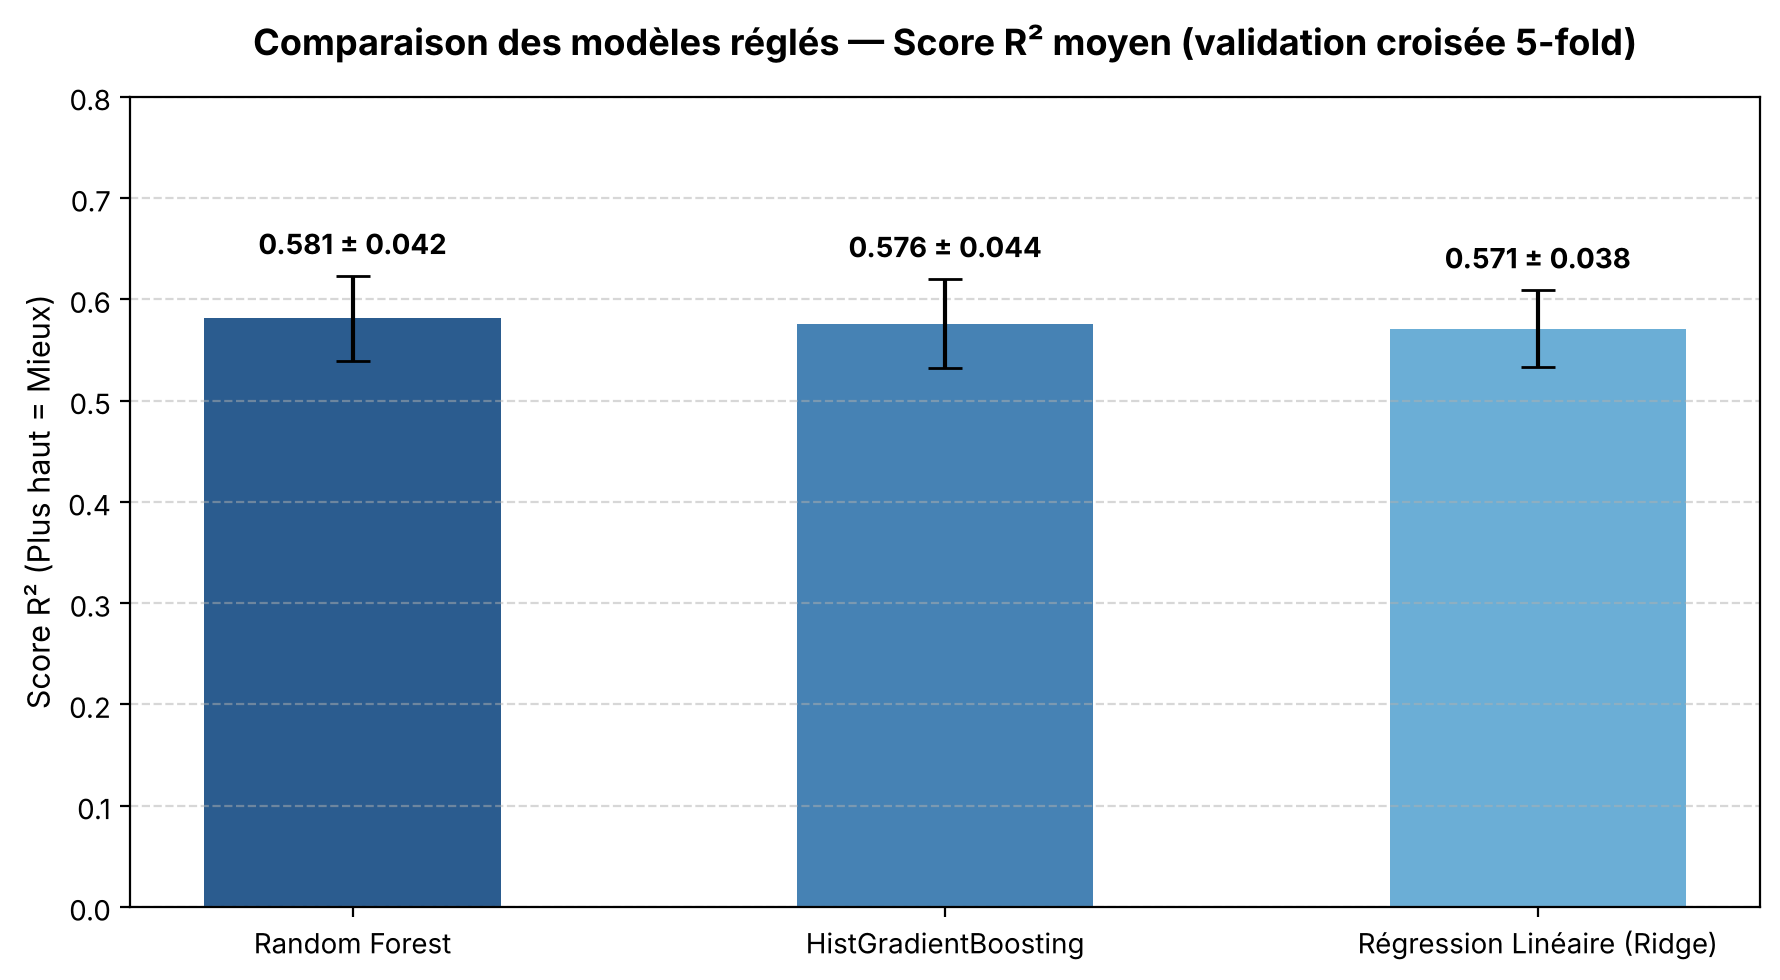

In [9]:
# ================================================================
# VISUALISATION FINALE : COMPARAISON DES MODÈLES RÉGLÉS (VALIDATION CROISÉE)
# ================================================================

import matplotlib.pyplot as plt

df_plot = df_tuned.sort_values(by='R² moyen (CV, réglé)', ascending=False).reset_index(drop=True)

labels_courts = {
    'Régression Linéaire (Ridge)': 'Régression Linéaire (Ridge)',
    'Random Forest (Forêt Aléatoire)': 'Random Forest',
    'HistGradientBoosting': 'HistGradientBoosting'
}
modeles_labels = [labels_courts.get(m, m) for m in df_plot['Modèle']]
scores_r2 = df_plot['R² moyen (CV, réglé)'].tolist()
erreurs_r2 = df_plot['R² écart-type (CV, réglé)'].tolist()

plt.figure(figsize=(9, 5))
barres = plt.bar(
    modeles_labels, scores_r2,
    yerr=erreurs_r2,
    capsize=6,
    color=['#2b5c8f', '#4682b4', '#6baed6'][:len(modeles_labels)],
    width=0.5
)

for barre, err in zip(barres, erreurs_r2):
    hauteur = barre.get_height()
    plt.text(barre.get_x() + barre.get_width()/2., hauteur + err + 0.015,
             f'{hauteur:.3f} ± {err:.3f}',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.ylim(0, 0.8)
plt.title('Comparaison des modèles réglés : Score R² moyen (validation croisée 5-fold)', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Score R² (Plus haut = Mieux)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Analyses complémentaires

Les cellules suivantes ne modifient aucun résultat précédent. Elles ajoutent : une référence naïve, la permutation importance du Random Forest réglé, l'analyse des erreurs par niveau de revenu, puis les pistes d'amélioration testées et non retenues.

In [10]:
from sklearn.dummy import DummyRegressor

# ================================================================
# RÉFÉRENCE NAÏVE : QUE VAUT UN MODÈLE QUI PRÉDIT TOUJOURS LA MOYENNE ?
# ================================================================
# Sans cette référence, une MAE de 7 000 € ne dit rien : il faut la comparer
# à l'erreur obtenue sans aucune variable explicative.

scores_naif = cross_validate(DummyRegressor(strategy='mean'), X, y, cv=cv,
                             scoring=['r2', 'neg_mean_absolute_error'])
mae_naive = -scores_naif['test_neg_mean_absolute_error'].mean()
mae_rf = float(df_tuned.loc[df_tuned['Modèle'] == NOM_RF, 'MAE moyen (CV, réglé, €)'].iloc[0])

print("="*70)
print(" RÉFÉRENCE NAÏVE (prédire le revenu moyen pour toutes les annonces)")
print("="*70)
print(f" R² moyen (CV)  : {scores_naif['test_r2'].mean():.3f}")
print(f" MAE moyen (CV) : {mae_naive:,.0f} €")
print(f" MAE du Random Forest réglé : {mae_rf:,.0f} €  →  erreur réduite de {(1 - mae_rf / mae_naive) * 100:.0f} %")

 RÉFÉRENCE NAÏVE (prédire le revenu moyen pour toutes les annonces)
 R² moyen (CV)  : -0.005
 MAE moyen (CV) : 11,250 €
 MAE du Random Forest réglé : 7,027 €  →  erreur réduite de 38 %


In [11]:
from sklearn.base import clone

# ================================================================
# IMPORTANCE DES FEATURES PAR PERMUTATION : RANDOM FOREST RÉGLÉ
# ================================================================
# Même protocole que pour Ridge plus haut (5 plis, 30 répétitions, mesure
# sur le pli de validation), mais appliqué au modèle retenu pour l'estimation.

importances_rf_par_fold = []

for train_idx, val_idx in cv_perm.split(X):
    pipeline_fold = clone(meilleurs_modeles[NOM_RF])
    pipeline_fold.fit(X.iloc[train_idx], y.iloc[train_idx])
    r = permutation_importance(
        pipeline_fold, X.iloc[val_idx], y.iloc[val_idx],
        n_repeats=30, random_state=42, scoring='r2', n_jobs=-1
    )
    importances_rf_par_fold.append(r.importances_mean)

df_importance_rf = pd.DataFrame({
    'Feature': features_reference,
    'Importance RF (perte de R²)': np.mean(importances_rf_par_fold, axis=0),
    'Ecart_type RF (5 plis)': np.std(importances_rf_par_fold, axis=0)
}).merge(
    df_importance[['Feature', 'Importance_moyenne (perte de R²)']].rename(
        columns={'Importance_moyenne (perte de R²)': 'Importance Ridge (rappel)'}),
    on='Feature'
).sort_values(by='Importance RF (perte de R²)', ascending=False)

print("="*70)
print(" IMPORTANCE PAR PERMUTATION : RANDOM FOREST RÉGLÉ (moyenne sur 5 plis)")
print("="*70)
print(df_importance_rf.round(3).to_string(index=False))
print("\n Attention : une importance mesure la dépendance du modèle à une variable,")
print(" pas un effet en euros, et elle se partage entre variables corrélées (chambres / voyageurs).")

 IMPORTANCE PAR PERMUTATION : RANDOM FOREST RÉGLÉ (moyenne sur 5 plis)
                Feature  Importance RF (perte de R²)  Ecart_type RF (5 plis)  Importance Ridge (rappel)
                  baths                        0.224                   0.051                      0.207
               bedrooms                        0.183                   0.132                      0.191
                   pool                        0.093                   0.013                      0.065
             dishwasher                        0.044                   0.012                      0.045
            num_reviews                        0.031                   0.014                      0.011
              superhost                        0.029                   0.012                      0.041
                 guests                        0.025                   0.009                      0.001
              bbq_grill                        0.013                   0.005                     

In [12]:
from sklearn.model_selection import cross_val_predict

# ================================================================
# OÙ LE MODÈLE SE TROMPE-T-IL ? ERREURS PAR NIVEAU DE REVENU RÉEL
# ================================================================
# Prédictions "hors pli" : chaque annonce est prédite par un modèle qui ne l'a pas vue.

pred_hors_pli = cross_val_predict(meilleurs_modeles[NOM_RF], X, y, cv=cv)

df_err = pd.DataFrame({'reel': y, 'predit': pred_hors_pli})
df_err['erreur'] = df_err['predit'] - df_err['reel']
df_err['quintile'] = pd.qcut(df_err['reel'], 5, labels=['Q1 (plus bas)', 'Q2', 'Q3', 'Q4', 'Q5 (plus haut)'])

df_quintiles = df_err.groupby('quintile', observed=True).agg(
    nb_annonces=('reel', 'size'),
    revenu_reel_moyen=('reel', 'mean'),
    biais_moyen=('erreur', 'mean'),
    mae=('erreur', lambda e: e.abs().mean())
).round(0)

print("="*70)
print(" ERREURS DU RANDOM FOREST RÉGLÉ PAR QUINTILE DE REVENU RÉEL")
print("="*70)
print(df_quintiles.to_string())
print("\n Biais positif = le modèle surestime ; biais négatif = il sous-estime.")
print(" Le modèle ramène les prédictions vers la moyenne : il surestime les petits")
print(" revenus et sous-estime nettement les biens les plus performants.")

 ERREURS DU RANDOM FOREST RÉGLÉ PAR QUINTILE DE REVENU RÉEL
                nb_annonces  revenu_reel_moyen  biais_moyen      mae
quintile                                                            
Q1 (plus bas)           233             9518.0       5775.0   5792.0
Q2                      232            14194.0       3570.0   4762.0
Q3                      233            19334.0       1486.0   4711.0
Q4                      232            27182.0      -1052.0   7240.0
Q5 (plus haut)          233            48163.0      -9954.0  12622.0

 Biais positif = le modèle surestime ; biais négatif = il sous-estime.
 Le modèle ramène les prédictions vers la moyenne : il surestime les petits
 revenus et sous-estime nettement les biens les plus performants.


# Pistes d'amélioration testées (non retenues)

Chaque piste est évaluée avec la même validation croisée que les modèles de référence. Une piste n'est retenue que si son gain dépasse la variabilité entre plis (écart-type du R² d'environ 0,04).

In [13]:
from sklearn.model_selection import RepeatedKFold

# ================================================================
# PISTE 1 : RATIOS DE "STANDING" (FEATURE ENGINEERING)
# ================================================================
# Idée : un bien haut de gamme offre plus de salles de bain par chambre ou
# par voyageur, et moins de voyageurs par chambre. On teste trois ratios.
# Le jeu de données ne contient pas le nombre de lits.

df_ratio = df_encoded.copy()
df_ratio['baths_per_bedroom'] = df_ratio['baths'] / df_ratio['bedrooms']
df_ratio['baths_per_guest'] = df_ratio['baths'] / df_ratio['guests']
df_ratio['guests_per_bedroom'] = df_ratio['guests'] / df_ratio['bedrooms']
ratios = ['baths_per_bedroom', 'baths_per_guest', 'guests_per_bedroom']

print(" Corrélation de Spearman de chaque ratio avec le revenu :")
print(df_ratio[ratios + ['ttm_revenue']].corr(method='spearman')['ttm_revenue'].drop('ttm_revenue').round(2).to_string())
print(f" Valeurs manquantes (héritées de bedrooms / guests) : {df_ratio[ratios].isna().sum().to_dict()}")

def pipeline_avec(modele_regle, variables_en_plus):
    """Même prétraitement que la référence, avec des variables continues supplémentaires."""
    pre = ColumnTransformer(transformers=[
        ('continues', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', RobustScaler())
        ]), cols_to_scale + variables_en_plus),
        ('binaires', SimpleImputer(strategy='median'), cols_binaires)
    ])
    return Pipeline([('preprocess', pre), ('model', clone(modele_regle))])

# Validation croisée répétée (5 plis x 10 répétitions) : 50 mesures par configuration,
# pour distinguer un vrai gain du hasard du découpage.
cv_repete = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

variantes = [('Référence (16 variables)', [])] + [(f'+ {r}', [r]) for r in ratios] + [('+ les trois ratios', ratios)]
resultats_ratio, scores_reference = [], {}

for nom_variante, en_plus in variantes:
    for nom, pipe_regle in meilleurs_modeles.items():
        modele_regle = pipe_regle.named_steps['model']
        X_var = df_ratio[features_reference + en_plus]
        s5 = cross_validate(pipeline_avec(modele_regle, en_plus), X_var, y, cv=cv,
                            scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)
        s50 = cross_validate(pipeline_avec(modele_regle, en_plus), X_var, y, cv=cv_repete,
                             scoring='r2', n_jobs=-1)['test_score']
        if not en_plus:
            scores_reference[nom] = s50
        delta = s50 - scores_reference[nom]
        resultats_ratio.append({
            'Variante': nom_variante,
            'Modèle': nom.split(' (')[0],
            'R² (5 plis)': round(s5['test_r2'].mean(), 3),
            'MAE (5 plis, €)': round(-s5['test_neg_mean_absolute_error'].mean()),
            'R² (5 plis x 10)': round(s50.mean(), 3),
            'Gain moyen de R²': round(delta.mean(), 4),
            'Ecart-type du gain': round(delta.std(), 4),
        })

df_ratios = pd.DataFrame(resultats_ratio)
print("\n" + "="*100)
print(" RATIOS DE STANDING : SCORES AVEC ET SANS (modèles réglés, mêmes hyperparamètres)")
print("="*100)
print(df_ratios.to_string(index=False))
print("\n Lecture : un gain n'est crédible que s'il est nettement supérieur à son écart-type")
print(" et à la variabilité entre plis (≈ 0,04). Sinon, il n'est pas distinguable du hasard.")

 Corrélation de Spearman de chaque ratio avec le revenu :
baths_per_bedroom    -0.23
baths_per_guest      -0.08
guests_per_bedroom   -0.12
 Valeurs manquantes (héritées de bedrooms / guests) : {'baths_per_bedroom': 101, 'baths_per_guest': 10, 'guests_per_bedroom': 102}



 RATIOS DE STANDING : SCORES AVEC ET SANS (modèles réglés, mêmes hyperparamètres)
                Variante               Modèle  R² (5 plis)  MAE (5 plis, €)  R² (5 plis x 10)  Gain moyen de R²  Ecart-type du gain
Référence (16 variables)  Régression Linéaire        0.571             7190             0.571            0.0000              0.0000
Référence (16 variables)        Random Forest        0.581             7027             0.568            0.0000              0.0000
Référence (16 variables) HistGradientBoosting        0.576             7084             0.564            0.0000              0.0000
     + baths_per_bedroom  Régression Linéaire        0.573             7176             0.574            0.0033              0.0074
     + baths_per_bedroom        Random Forest        0.582             7006             0.568           -0.0000              0.0067
     + baths_per_bedroom HistGradientBoosting        0.575             7057             0.568            0.0032              

In [14]:
# ================================================================
# PISTE 2 : AUTRES VARIABLES DÉRIVÉES (Ridge)
# ================================================================
# log du nombre d'avis, nombre total d'équipements, indicateur "grande villa".

pipeline_normal = Pipeline([('preprocess', preprocesseur), ('model', Ridge(alpha=10.0))])
scores_normal = cross_validate(pipeline_normal, X, y, cv=cv, scoring='r2', n_jobs=-1)

df_fe = df_encoded.copy()
df_fe['log_num_reviews'] = np.log1p(df_fe['num_reviews'])

equip_cols = ['pool','air_conditioning','dishwasher','dedicated_workspace',
              'waterfront','hot_tub','bbq_grill','cable_tv','gym']
df_fe['nb_equipements'] = df_fe[equip_cols].sum(axis=1)
df_fe['grande_villa'] = (df_fe['bedrooms'] >= 4).astype(int)

# On remplace num_reviews (brut) par sa version log : pas les deux, pour éviter la redondance
features_fe = [f for f in features_reference if f != 'num_reviews']
features_fe += ['log_num_reviews', 'nb_equipements', 'grande_villa']

cols_a_scaler_fe = [c for c in cols_to_scale if c != 'num_reviews'] + ['log_num_reviews', 'nb_equipements']
cols_binaires_fe = [c for c in features_fe if c not in cols_a_scaler_fe]

preprocesseur_fe = ColumnTransformer(transformers=[
    ('continues', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), cols_a_scaler_fe),
    ('binaires', SimpleImputer(strategy='median'), cols_binaires_fe)
])

pipeline_fe = Pipeline([('preprocess', preprocesseur_fe), ('model', Ridge(alpha=10.0))])
scores_fe = cross_validate(pipeline_fe, df_fe[features_fe], y, cv=cv,
                           scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)

print("="*70)
print(" PISTE 2 : SANS vs AVEC VARIABLES DÉRIVÉES (Ridge, alpha = 10)")
print("="*70)
print(f" Sans : R² = {scores_normal['test_score'].mean():.3f} ± {scores_normal['test_score'].std():.3f}")
print(f" Avec : R² = {scores_fe['test_r2'].mean():.3f} ± {scores_fe['test_r2'].std():.3f}"
      f" | MAE = {-scores_fe['test_neg_mean_absolute_error'].mean():,.0f} €")

 PISTE 2 : SANS vs AVEC VARIABLES DÉRIVÉES (Ridge, alpha = 10)
 Sans : R² = 0.571 ± 0.038
 Avec : R² = 0.575 ± 0.037 | MAE = 7,150 €


In [15]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# ================================================================
# PISTE 3 : SEGMENTATION NON SUPERVISÉE (KMeans), sans utiliser le revenu
# ================================================================
# On détecte des groupes de logements (taille + équipements) SANS regarder
# ttm_revenue, puis on ajoute le segment comme variable.

segment_cols = ['bedrooms', 'guests', 'baths', 'pool', 'air_conditioning',
                'dishwasher', 'dedicated_workspace', 'waterfront', 'hot_tub',
                'bbq_grill', 'cable_tv', 'gym']

df_seg_imputed = SimpleImputer(strategy='median').fit_transform(df_encoded[segment_cols])
df_seg_scaled = StandardScaler().fit_transform(df_seg_imputed)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_fe2 = df_encoded.copy()
df_fe2['segment_bien'] = kmeans.fit_predict(df_seg_scaled)

print(" Répartition des segments détectés :")
print(df_fe2['segment_bien'].value_counts().sort_index().to_string())
print("\n Caractéristiques moyennes par segment :")
print(df_fe2.groupby('segment_bien')[['bedrooms', 'baths', 'pool', 'waterfront']].mean().round(2).to_string())

df_fe2 = pd.get_dummies(df_fe2, columns=['segment_bien'], prefix='segment', dtype=int)
segment_dummy_cols = [c for c in df_fe2.columns if c.startswith('segment_')]
features_fe2 = features_reference + segment_dummy_cols
cols_binaires_fe2 = [c for c in features_fe2 if c not in cols_to_scale]

preprocesseur_fe2 = ColumnTransformer(transformers=[
    ('continues', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ]), cols_to_scale),
    ('binaires', SimpleImputer(strategy='median'), cols_binaires_fe2)
])

pipeline_fe2 = Pipeline([('preprocess', preprocesseur_fe2), ('model', Ridge(alpha=10.0))])
scores_fe2 = cross_validate(pipeline_fe2, df_fe2[features_fe2], y, cv=cv, scoring='r2', n_jobs=-1)

print("\n" + "="*70)
print(" PISTE 3 : SANS vs AVEC SEGMENTATION KMeans (Ridge, alpha = 10)")
print("="*70)
print(f" Sans : R² = {scores_normal['test_score'].mean():.3f} ± {scores_normal['test_score'].std():.3f}")
print(f" Avec : R² = {scores_fe2['test_score'].mean():.3f} ± {scores_fe2['test_score'].std():.3f}")

 Répartition des segments détectés :
segment_bien
0    710
1    251
2    202

 Caractéristiques moyennes par segment :
              bedrooms  baths  pool  waterfront
segment_bien                                   
0                 1.33   1.07  0.54        0.19
1                 3.16   2.42  0.89        0.19
2                 1.43   1.17  0.66        0.89

 PISTE 3 : SANS vs AVEC SEGMENTATION KMeans (Ridge, alpha = 10)
 Sans : R² = 0.571 ± 0.038
 Avec : R² = 0.573 ± 0.040


In [16]:
from sklearn.compose import TransformedTargetRegressor

# ================================================================
# PISTE 4 : TRANSFORMATION LOGARITHMIQUE DE LA CIBLE
# ================================================================
# Le revenu est asymétrique (moyenne > médiane). On entraîne sur log(1 + revenu)
# puis on revient en euros pour mesurer R² et MAE sur l'échelle d'origine.

print(f" Asymétrie (skewness) du revenu : {y.skew():.2f} | de log(1 + revenu) : {np.log1p(y).skew():.2f}")
print("="*70)
print(" PISTE 4 : CIBLE EN EUROS vs CIBLE EN LOG (scores mesurés en euros)")
print("="*70)

for nom, pipe_regle in meilleurs_modeles.items():
    s_eur = cross_validate(clone(pipe_regle), X, y, cv=cv, scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)
    modele_log = TransformedTargetRegressor(regressor=clone(pipe_regle), func=np.log1p, inverse_func=np.expm1)
    s_log = cross_validate(modele_log, X, y, cv=cv, scoring=['r2', 'neg_mean_absolute_error'], n_jobs=-1)
    print(f" {nom.split(' (')[0]:<22} euros : R² = {s_eur['test_r2'].mean():.3f} ± {s_eur['test_r2'].std():.3f},"
          f" MAE = {-s_eur['test_neg_mean_absolute_error'].mean():,.0f} €"
          f"  |  log : R² = {s_log['test_r2'].mean():.3f} ± {s_log['test_r2'].std():.3f},"
          f" MAE = {-s_log['test_neg_mean_absolute_error'].mean():,.0f} €")

 Asymétrie (skewness) du revenu : 1.51 | de log(1 + revenu) : 0.23
 PISTE 4 : CIBLE EN EUROS vs CIBLE EN LOG (scores mesurés en euros)


 Régression Linéaire    euros : R² = 0.571 ± 0.038, MAE = 7,190 €  |  log : R² = 0.498 ± 0.069, MAE = 7,200 €


 Random Forest          euros : R² = 0.581 ± 0.042, MAE = 7,027 €  |  log : R² = 0.570 ± 0.041, MAE = 6,945 €


 HistGradientBoosting   euros : R² = 0.576 ± 0.044, MAE = 7,084 €  |  log : R² = 0.566 ± 0.050, MAE = 6,984 €


# Conclusion des pistes testées

| Piste | Résultat en validation croisée | Décision |
|---|---|---|
| 1. Ratios de standing | Gain moyen de R² compris entre −0,005 et +0,003 selon le ratio et le modèle, avec un écart-type du gain de 0,001 à 0,012 | Non retenu |
| 2. Variables dérivées (log des avis, nombre d'équipements, grande villa) | Ridge : R² de 0,571 à 0,575 | Non retenu |
| 3. Segmentation KMeans | Ridge : R² de 0,571 à 0,573 | Non retenu |
| 4. Cible en logarithme | Ridge : R² de 0,571 à 0,498. Random Forest : R² de 0,581 à 0,570, MAE de 7 027 € à 6 945 €. HistGradientBoosting : R² de 0,576 à 0,566, MAE de 7 084 € à 6 984 € | Non retenu |

Lecture. Aucune piste n'apporte un gain supérieur à la variabilité entre plis (écart-type du R² d'environ 0,04).

- Les ratios sont corrélés *négativement* au revenu (−0,23 pour les salles de bain par chambre). Ils mesurent surtout l'inverse de la taille du bien : une grande villa a moins de salles de bain par chambre qu'un studio. L'information utile est déjà portée par `bedrooms`, `baths` et `guests`.
- La segmentation KMeans retrouve des groupes déjà décrits par les variables existantes (grandes villas, petits biens en front de mer).
- La cible en logarithme réduit l'asymétrie (de 1,51 à 0,23) et améliore légèrement la MAE des modèles à base d'arbres (environ 1 %), mais dégrade le R² des trois modèles, nettement pour Ridge. Le retour en euros par exponentielle n'est pas corrigé de son biais.
- En validation croisée répétée (5 plis × 10), les trois modèles de référence obtiennent 0,571 (Ridge), 0,568 (Random Forest) et 0,564 (HistGradientBoosting) : leur classement dépend du découpage, ils sont à égalité.

Conclusion. Recombiner les colonnes numériques existantes n'apporte rien : l'information y est déjà. Pour progresser, il faut une information nouvelle. C'est l'objet de la section suivante, qui exploite deux sources négligées jusqu'ici : la signification des chambres manquantes et le titre de l'annonce.

# Modèle amélioré : comprendre les erreurs avant de changer d'algorithme

Les quatre pistes précédentes reformulaient des variables déjà présentes. Les deux suivantes apportent une information nouvelle :

1. Les chambres manquantes ne sont pas manquantes au hasard. Ce sont des studios. Les imputer par la médiane (1 chambre) est une erreur de traitement.
2. Le titre de l'annonce décrit le type et le standing du bien (villa, studio, vue mer, luxe). C'est du text mining simple par mots-clés.

On teste ensuite XGBoost, et on mesure le gain par une validation croisée imbriquée, qui ne réutilise pas les mêmes plis pour régler et pour évaluer.

In [17]:
# ================================================================
# ÉTAPE A : LES CHAMBRES MANQUANTES SONT DES STUDIOS
# ================================================================
df_plus = df_encoded.copy()
masque_sans_chambre = df_plus['bedrooms'].isna()
titres = df_plus['listing_name'].astype(str).str.lower()

print(f" Annonces sans nombre de chambres : {masque_sans_chambre.sum()} | plus petit nombre de chambres renseigné : {df_plus['bedrooms'].min():.0f}")
print(" Capacité (voyageurs) de ces annonces :", df_plus.loc[masque_sans_chambre, 'guests'].value_counts().sort_index().to_dict())
print(f" Part de titres contenant 'studio' : {titres[masque_sans_chambre].str.contains('studio').mean():.0%} quand bedrooms est manquant,"
      f" {titres[df_plus['bedrooms'] == 1].str.contains('studio').mean():.0%} quand bedrooms = 1")
print(f" Revenu médian : {df_plus.loc[masque_sans_chambre, 'ttm_revenue'].median():,.0f} € sans chambre renseignée,"
      f" {df_plus.loc[df_plus['bedrooms'] == 1, 'ttm_revenue'].median():,.0f} € avec 1 chambre")

# Aucune annonce n'a 0 chambre : la source code les studios par une valeur manquante.
# On les recode donc à 0 chambre au lieu de les imputer à la médiane (1 chambre).
df_plus['bedrooms'] = df_plus['bedrooms'].fillna(0)

 Annonces sans nombre de chambres : 101 | plus petit nombre de chambres renseigné : 1
 Capacité (voyageurs) de ces annonces : {2.0: 51, 3.0: 16, 4.0: 24, 5.0: 1}
 Part de titres contenant 'studio' : 63% quand bedrooms est manquant, 25% quand bedrooms = 1
 Revenu médian : 13,118 € sans chambre renseignée, 15,248 € avec 1 chambre


In [18]:
# ================================================================
# ÉTAPE B : TEXT MINING : MOTS-CLÉS DU TITRE DE L'ANNONCE
# ================================================================
# Liste fixée à partir des mots les plus fréquents des titres, SANS regarder le revenu.
# Chaque variable vaut 1 si le titre contient l'un des termes (expression régulière).

MOTS_CLES = {
    't_villa':    r'villa',
    't_studio':   r'studio',
    't_appart':   r'apartment|appartement|\bt[1-4]\b|\bf[1-4]\b|flat|duplex',
    't_bungalow': r'bungalow|cottage|\bkaz\b|\bcase\b|gite|gîte|lodge',
    't_house':    r'house|maison',
    't_sea':      r'sea ?view|vue mer|ocean|lagoon|lagon|panoram',
    't_beach':    r'beach|plage|beachfront|waterfront|feet in the water|pieds dans',
    't_luxe':     r'luxury|luxe|standing|prestige|exceptional|premium|chic|architect|haut de gamme|5 ?\*|star',
    't_pool':     r'pool|piscine',
    't_private':  r'private|privée|privative',
    't_marina':   r'marina|golf',
    't_jacuzzi':  r'jacuzzi|spa|hot tub',
}
for nom_var, motif in MOTS_CLES.items():
    df_plus[nom_var] = titres.str.contains(motif, regex=True).astype(int)

cols_titre = list(MOTS_CLES)
features_plus = features_reference + cols_titre
cols_binaires_plus = cols_binaires + cols_titre
X_plus = df_plus[features_plus]

print(" Nombre d'annonces concernées par mot-clé :")
print(df_plus[cols_titre].sum().to_string())

def preprocesseur_plus():
    return ColumnTransformer(transformers=[
        ('continues', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', RobustScaler())
        ]), cols_to_scale),
        ('binaires', SimpleImputer(strategy='median'), cols_binaires_plus)
    ])

# Lecture en euros : Ridge avec les nouvelles variables (même alpha que le modèle réglé)
alpha_regle = meilleurs_modeles["Régression Linéaire (Ridge)"].named_steps['model'].alpha
ridge_plus = Pipeline([('preprocess', preprocesseur_plus()), ('model', Ridge(alpha=alpha_regle))])
s_ridge_plus = cross_validate(ridge_plus, X_plus, y, cv=cv, scoring=['r2', 'neg_mean_absolute_error'])
ridge_plus.fit(X_plus, y)
coefs_plus = pd.Series(ridge_plus.named_steps['model'].coef_, index=cols_to_scale + cols_binaires_plus)

print(f"\n Ridge avec studios à 0 chambre et mots-clés : R² = {s_ridge_plus['test_r2'].mean():.3f} ± {s_ridge_plus['test_r2'].std():.3f}"
      f" | MAE = {-s_ridge_plus['test_neg_mean_absolute_error'].mean():,.0f} €  (référence : 0.571, 7,190 €)")
print("\n Effet associé à chaque mot-clé, à caractéristiques égales (€/an, Ridge sur toutes les annonces) :")
print(coefs_plus[cols_titre].sort_values(ascending=False).round(0).to_string())

scaler_plus = ridge_plus.named_steps['preprocess'].named_transformers_['continues'].named_steps['scaler']
print("\n Tous les coefficients du Ridge amélioré (28 variables, €/an) :")
print(coefs_plus.sort_values(ascending=False).round(0).to_string())
print(f" Constante (intercept) : {ridge_plus.named_steps['model'].intercept_:,.0f} €")
print(" Variables continues : coefficient pour une variation d'un écart interquartile : "
      + ", ".join(f"{c} = {e:g}" for c, e in zip(cols_to_scale, scaler_plus.scale_)))

 Nombre d'annonces concernées par mot-clé :
t_villa       273
t_studio      197
t_appart      209
t_bungalow    191
t_house        49
t_sea         206
t_beach       337
t_luxe         58
t_pool        312
t_private     102
t_marina       41
t_jacuzzi      48

 Ridge avec studios à 0 chambre et mots-clés : R² = 0.589 ± 0.047 | MAE = 7,056 €  (référence : 0.571, 7,190 €)

 Effet associé à chaque mot-clé, à caractéristiques égales (€/an, Ridge sur toutes les annonces) :
t_villa       4573.0
t_sea         2898.0
t_luxe        2046.0
t_jacuzzi      713.0
t_pool         462.0
t_beach        353.0
t_bungalow    -621.0
t_appart     -1269.0
t_private    -1281.0
t_marina     -1582.0
t_house      -2537.0
t_studio     -2874.0

 Tous les coefficients du Ridge amélioré (28 variables, €/an) :
pool                       5284.0
t_villa                    4573.0
dishwasher                 4051.0
superhost                  3788.0
bedrooms                   3076.0
air_conditioning           2967.0
t_sea 

In [19]:
from xgboost import XGBRegressor
from scipy.stats import loguniform

# ================================================================
# ÉTAPE C : XGBOOST ET RÉGLAGE, AVEC LES NOUVELLES VARIABLES
# ================================================================
espace_xgb = {
    'model__n_estimators': randint(150, 700),
    'model__learning_rate': loguniform(0.01, 0.15),
    'model__max_depth': randint(2, 6),
    'model__subsample': uniform(0.6, 0.4),
    'model__colsample_bytree': uniform(0.5, 0.5),
    'model__min_child_weight': randint(1, 10),
    'model__reg_lambda': loguniform(0.5, 20),
}
espace_rf_plus = {
    'model__n_estimators': randint(100, 250),
    'model__max_depth': randint(3, 15),
    'model__min_samples_leaf': randint(1, 10),
    'model__max_features': uniform(0.2, 0.6),   # non exploré dans la première recherche
}
candidats_plus = {
    "XGBoost + titre": (Pipeline([('preprocess', preprocesseur_plus()), ('model', XGBRegressor(random_state=42, n_jobs=1))]), espace_xgb, 20),
    "Random Forest + titre": (Pipeline([('preprocess', preprocesseur_plus()), ('model', RandomForestRegressor(random_state=42, n_jobs=1))]), espace_rf_plus, 20),
}

resultats_plus, modeles_plus = [], {}
for nom, (pipe, espace, n_iter) in candidats_plus.items():
    recherche = RandomizedSearchCV(pipe, espace, n_iter=n_iter, cv=cv, scoring='r2', random_state=42, n_jobs=-1)
    recherche.fit(X_plus, y)
    modeles_plus[nom] = recherche.best_estimator_
    s = cross_validate(recherche.best_estimator_, X_plus, y, cv=cv,
                       scoring=['r2', 'neg_mean_absolute_error'], return_train_score=True)
    resultats_plus.append({
        'Modèle': nom,
        'R² moyen (CV, réglé)': round(s['test_r2'].mean(), 3),
        'R² écart-type': round(s['test_r2'].std(), 3),
        'R² entraînement': round(s['train_r2'].mean(), 3),
        'MAE moyen (CV, réglé, €)': round(-s['test_neg_mean_absolute_error'].mean()),
    })
    print(f" {nom} : meilleurs hyperparamètres : { {k.replace('model__', ''): (round(float(v), 4) if isinstance(v, float) else int(v)) for k, v in recherche.best_params_.items()} }")

df_plus_res = pd.concat([
    df_tuned[['Modèle', 'R² moyen (CV, réglé)', 'MAE moyen (CV, réglé, €)']].assign(Variables='16 de référence'),
    pd.DataFrame(resultats_plus)[['Modèle', 'R² moyen (CV, réglé)', 'MAE moyen (CV, réglé, €)']].assign(Variables='16 + studios à 0 + 12 mots-clés'),
]).sort_values('R² moyen (CV, réglé)', ascending=False)

print("\n" + "="*90)
print(" COMPARAISON SUR LES MÊMES 5 PLIS (scores après réglage, donc légèrement optimistes)")
print("="*90)
print(df_plus_res.to_string(index=False))
print("\n Détail des nouveaux modèles :")
print(pd.DataFrame(resultats_plus).to_string(index=False))

 XGBoost + titre : meilleurs hyperparamètres : {'colsample_bytree': 0.716, 'learning_rate': 0.022, 'max_depth': 4, 'min_child_weight': 3, 'n_estimators': 393, 'reg_lambda': 4.4469, 'subsample': 0.6186}


 Random Forest + titre : meilleurs hyperparamètres : {'max_depth': 11, 'max_features': 0.3778, 'min_samples_leaf': 1, 'n_estimators': 188}

 COMPARAISON SUR LES MÊMES 5 PLIS (scores après réglage, donc légèrement optimistes)
                         Modèle  R² moyen (CV, réglé)  MAE moyen (CV, réglé, €)                       Variables
                XGBoost + titre                 0.624                    6657.0 16 + studios à 0 + 12 mots-clés
          Random Forest + titre                 0.609                    6821.0 16 + studios à 0 + 12 mots-clés
Random Forest (Forêt Aléatoire)                 0.581                    7027.0                 16 de référence
           HistGradientBoosting                 0.576                    7084.0                 16 de référence
    Régression Linéaire (Ridge)                 0.571                    7190.0                 16 de référence

 Détail des nouveaux modèles :
               Modèle  R² moyen (CV, réglé)  R² écart-type  R² entraîne

In [20]:
from sklearn.metrics import r2_score, mean_absolute_error

# ================================================================
# ÉTAPE D : MESURE SANS BIAIS : VALIDATION CROISÉE IMBRIQUÉE
# ================================================================
# Jusqu'ici, les mêmes plis servent à choisir les hyperparamètres et à noter le modèle.
# Ici, chaque pli externe est noté par un modèle réglé UNIQUEMENT sur les autres plis
# (recherche aléatoire interne). 5 plis externes x 2 répétitions = 10 mesures.

cv_externe = RepeatedKFold(n_splits=5, n_repeats=2, random_state=7)

def validation_imbriquee(pipe, espace, X_data, n_iter):
    r2s, maes = [], []
    for i, (idx_train, idx_test) in enumerate(cv_externe.split(X_data)):
        cv_interne = KFold(n_splits=5, shuffle=True, random_state=100 + i)
        recherche = RandomizedSearchCV(clone(pipe), espace, n_iter=n_iter, cv=cv_interne,
                                       scoring='r2', random_state=42, n_jobs=-1)
        recherche.fit(X_data.iloc[idx_train], y.iloc[idx_train])
        pred = recherche.predict(X_data.iloc[idx_test])
        r2s.append(r2_score(y.iloc[idx_test], pred))
        maes.append(mean_absolute_error(y.iloc[idx_test], pred))
    return np.array(r2s), np.array(maes)

pipe_rf_ref = Pipeline([('preprocess', preprocesseur), ('model', RandomForestRegressor(random_state=42, n_jobs=1))])
r2_ref, mae_ref = validation_imbriquee(pipe_rf_ref, espaces_recherche[NOM_RF]['params'], X, 15)
r2_xgb, mae_xgb = validation_imbriquee(candidats_plus["XGBoost + titre"][0], espace_xgb, X_plus, 20)

print("="*90)
print(" VALIDATION CROISÉE IMBRIQUÉE (10 mesures, réglage refait à l'intérieur de chaque pli)")
print("="*90)
print(f" Random Forest du notebook (16 variables) : R² = {r2_ref.mean():.3f} ± {r2_ref.std():.3f} | MAE = {mae_ref.mean():,.0f} €")
print(f" XGBoost + studios à 0 + mots-clés        : R² = {r2_xgb.mean():.3f} ± {r2_xgb.std():.3f} | MAE = {mae_xgb.mean():,.0f} €")
gain = r2_xgb - r2_ref
print(f"\n Gain de R² : {gain.mean():+.3f} (écart-type du gain {gain.std():.3f}), positif sur {(gain > 0).sum()} mesures sur {len(gain)}")
print(f" Gain de MAE : {(mae_xgb - mae_ref).mean():+,.0f} € ({(mae_xgb.mean() / mae_ref.mean() - 1) * 100:+.1f} %)")
print(f" Écart entre score réglé (optimiste) et score imbriqué pour le Random Forest : "
      f"{float(df_tuned.loc[df_tuned['Modèle'] == NOM_RF, 'R² moyen (CV, réglé)'].iloc[0]) - r2_ref.mean():+.3f}")

 VALIDATION CROISÉE IMBRIQUÉE (10 mesures, réglage refait à l'intérieur de chaque pli)
 Random Forest du notebook (16 variables) : R² = 0.560 ± 0.041 | MAE = 7,123 €
 XGBoost + studios à 0 + mots-clés        : R² = 0.604 ± 0.033 | MAE = 6,816 €

 Gain de R² : +0.044 (écart-type du gain 0.018), positif sur 10 mesures sur 10
 Gain de MAE : -307 € (-4.3 %)
 Écart entre score réglé (optimiste) et score imbriqué pour le Random Forest : +0.021


In [21]:
# ================================================================
# ÉTAPE E : LE MODÈLE AMÉLIORÉ : IMPORTANCE, ERREURS, USAGE "BIEN NEUF", SAUVEGARDE
# ================================================================
NOM_XGB = "XGBoost + titre"
modele_final = modeles_plus[NOM_XGB]

# 1. Importance par permutation (même protocole que plus haut)
imp_xgb = []
for train_idx, val_idx in cv_perm.split(X_plus):
    p = clone(modele_final).fit(X_plus.iloc[train_idx], y.iloc[train_idx])
    r = permutation_importance(p, X_plus.iloc[val_idx], y.iloc[val_idx], n_repeats=30, random_state=42, scoring='r2', n_jobs=-1)
    imp_xgb.append(r.importances_mean)
df_imp_xgb = pd.DataFrame({'Feature': features_plus, 'Importance (perte de R²)': np.mean(imp_xgb, axis=0),
                           'Ecart_type (5 plis)': np.std(imp_xgb, axis=0)}).sort_values('Importance (perte de R²)', ascending=False)
print("="*70)
print(" IMPORTANCE PAR PERMUTATION : XGBOOST + TITRE (12 premières variables)")
print("="*70)
print(df_imp_xgb.head(12).round(3).to_string(index=False))

# 2. Erreurs par quintile, comparées au Random Forest de référence
pred_xgb = cross_val_predict(modele_final, X_plus, y, cv=cv)
df_err['erreur_xgb'] = pred_xgb - df_err['reel']
df_q2 = df_err.groupby('quintile', observed=True).agg(
    biais_rf=('erreur', 'mean'), biais_xgb=('erreur_xgb', 'mean'),
    mae_rf=('erreur', lambda e: e.abs().mean()), mae_xgb=('erreur_xgb', lambda e: e.abs().mean())).round(0)
print("\n" + "="*70)
print(" ERREURS PAR QUINTILE : RANDOM FOREST DE RÉFÉRENCE vs XGBOOST + TITRE")
print("="*70)
print(df_q2.to_string())

# 3. Usage "bien jamais loué" : le même modèle sans le nombre d'avis ni le statut Superhost
features_neuf = [f for f in features_plus if f not in ('num_reviews', 'superhost')]
pre_neuf = ColumnTransformer(transformers=[
    ('continues', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', RobustScaler())]),
     [c for c in cols_to_scale if c != 'num_reviews']),
    ('binaires', SimpleImputer(strategy='median'), [c for c in cols_binaires_plus if c != 'superhost'])
])
modele_neuf = Pipeline([('preprocess', pre_neuf), ('model', clone(modele_final.named_steps['model']))])
s_neuf = cross_validate(modele_neuf, df_plus[features_neuf], y, cv=cv, scoring=['r2', 'neg_mean_absolute_error'])
print("\n" + "="*70)
print(" VARIANTE POUR UN BIEN JAMAIS LOUÉ (sans avis ni Superhost)")
print("="*70)
print(f" R² = {s_neuf['test_r2'].mean():.3f} ± {s_neuf['test_r2'].std():.3f} | MAE = {-s_neuf['test_neg_mean_absolute_error'].mean():,.0f} €")

# 4. Sauvegarde du pipeline complet, réajusté sur toutes les annonces
chemin_xgb = os.path.join(PROJECT_DIR, 'modele_xgboost_titre.pkl')
joblib.dump({'modele': modele_final, 'features': features_plus, 'mots_cles': MOTS_CLES}, chemin_xgb)
print(f"\n Modèle amélioré sauvegardé dans : {chemin_xgb}")

 IMPORTANCE PAR PERMUTATION : XGBOOST + TITRE (12 premières variables)
            Feature  Importance (perte de R²)  Ecart_type (5 plis)
              baths                     0.167                0.027
           bedrooms                     0.109                0.026
               pool                     0.077                0.009
         dishwasher                     0.041                0.008
          superhost                     0.033                0.011
            t_villa                     0.032                0.011
        num_reviews                     0.026                0.014
             guests                     0.020                0.003
              t_sea                     0.013                0.003
          t_private                     0.010                0.003
           t_studio                     0.007                0.003
dedicated_workspace                     0.007                0.005



 ERREURS PAR QUINTILE : RANDOM FOREST DE RÉFÉRENCE vs XGBOOST + TITRE
                biais_rf  biais_xgb   mae_rf  mae_xgb
quintile                                             
Q1 (plus bas)     5775.0     5332.0   5792.0   5446.0
Q2                3570.0     2926.0   4762.0   4167.0
Q3                1486.0     1692.0   4711.0   4624.0
Q4               -1052.0     -998.0   7240.0   6862.0
Q5 (plus haut)   -9954.0    -9255.0  12622.0  12175.0



 VARIANTE POUR UN BIEN JAMAIS LOUÉ (sans avis ni Superhost)
 R² = 0.597 ± 0.053 | MAE = 6,914 €

 Modèle amélioré sauvegardé dans : ./modele_xgboost_titre.pkl


# Conclusion : modèle retenu

| | Première version | Modèle amélioré |
|---|---|---|
| Algorithme | Random Forest réglé | XGBoost réglé |
| Variables | 16 | 28 (les 16, plus 12 mots-clés du titre) |
| Chambres manquantes | imputées à 1 (médiane) | recodées à 0 (studios) |
| R², validation croisée après réglage | 0,581 ± 0,042 | 0,624 ± 0,047 |
| MAE, validation croisée après réglage | 7 027 € | 6 657 € |
| R², validation croisée imbriquée | 0,560 ± 0,041 | 0,604 ± 0,033 |
| MAE, validation croisée imbriquée | 7 123 € | 6 816 € |

Ce qu'il faut retenir.

- Le gain vient des données, pas de l'algorithme : avec les mêmes 16 variables, XGBoost ne fait pas mieux que les autres modèles de façon nette. Ce sont les mots-clés du titre (villa, studio, vue mer) et le recodage des studios qui apportent l'information.
- Le chiffre à citer est celui de la validation croisée imbriquée : R² de 0,604 et erreur moyenne de 6 816 €, contre 0,560 et 7 123 € pour la première version mesurée de la même façon. Le gain de R² est de +0,044, positif sur 10 mesures sur 10. Les scores « après réglage » sont optimistes d'environ 0,02.
- Par rapport à une prédiction naïve (MAE de 11 250 €), l'erreur est réduite de 39 %.
- Sans le nombre d'avis ni le statut Superhost, le modèle atteint encore un R² de 0,597 (MAE de 6 914 €) : il reste utilisable pour un bien jamais loué.
- Le défaut principal demeure : les biens les plus performants sont sous-estimés d'environ 9 300 € en moyenne.

Limites de ces nouvelles variables. Les mots-clés viennent d'une extraction simple par expressions régulières sur des titres parfois traduits ou peu soignés. Leurs coefficients sont des associations : écrire « villa » dans un titre n'augmente pas le revenu. L'API AirROI fournit un type de bien structuré, des coordonnées GPS et des notes, qui seraient préférables.